# Practical 9: K-Nearest Neighbours Classification

**Dataset:** Iris (150 flowers, 4 measurements, 3 species)

**Aim:** Classify iris species with KNN, evaluate the model, find the best value of K and plot the decision regions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

iris = pd.read_csv("iris.csv")
iris.head()

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

In [2]:
iris.info()
print(iris["species"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Result:** The data has 150 rows and no missing values. Each species has 50 flowers, so the classes are perfectly balanced.

In [3]:
iris.describe().round(3)

       sepal_length  sepal_width  petal_length  petal_width
count       150.000      150.000       150.000      150.000
mean          5.843        3.057         3.758        1.199
std           0.828        0.436         1.765        0.762
min           4.300        2.000         1.000        0.100
25%           5.100        2.800         1.600        0.300
50%           5.800        3.000         4.350        1.300
75%           6.400        3.300         5.100        1.800
max           7.900        4.400         6.900        2.500

In [4]:
species_mean = iris.groupby("species").mean().round(3)
species_mean

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             5.006        3.428         1.462        0.246
versicolor         5.936        2.770         4.260        1.326
virginica          6.588        2.974         5.552        2.026

**Result:** Setosa has the smallest petals, virginica has the largest and versicolor lies in between. Petal measurements separate the species better than sepal measurements.

In [5]:
features = iris.drop(columns="species").to_numpy()
labels = iris["species"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42, stratify=labels)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "Test:", X_test_s.shape)

Train: (120, 4) Test: (30, 4)


**Result:** The data was split into 120 training and 30 test flowers, and all features were standardized using the training data.

In [6]:
knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
pred5 = knn5.predict(X_test_s)
cm = confusion_matrix(y_test, pred5)
acc5 = accuracy_score(y_test, pred5)
print(cm)
print("Accuracy:", round(acc5, 4))
print(classification_report(y_test, pred5))

[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



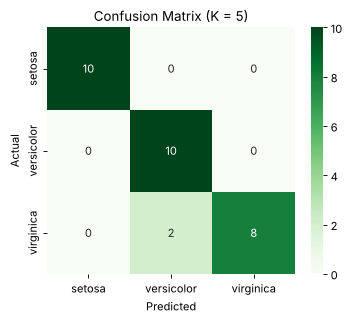

In [7]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=knn5.classes_, yticklabels=knn5.classes_)
plt.title("Confusion Matrix (K = 5)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Result:** With K = 5 the accuracy is 93.33%. The diagonal of the matrix shows correct predictions and 2 flowers were misclassified, all between versicolor and virginica.

In [8]:
ks = list(range(1, 31))
cv_error = [1 - cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5).mean() for k in ks]
error_table = pd.DataFrame({"K": ks, "Error rate": np.round(cv_error, 4)})
print(error_table.to_string(index=False))

 K  Error rate
 1      0.0583
 2      0.0417
 3      0.0417
 4      0.0417
 5      0.0333
 6      0.0333
 7      0.0417
 8      0.0417
 9      0.0417
10      0.0333
11      0.0417
12      0.0333
13      0.0500
14      0.0417
15      0.0500
16      0.0417
17      0.0417
18      0.0583
19      0.0583
20      0.0667
21      0.0667
22      0.0750
23      0.0750
24      0.0917
25      0.1083
26      0.0917
27      0.1000
28      0.1083
29      0.1083
30      0.1083


Best K: 5
Lowest error: 0.0333


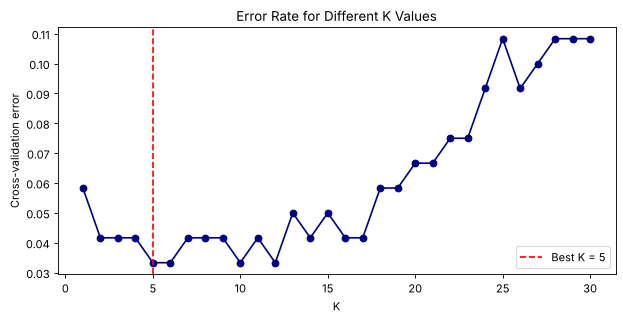

In [9]:
best_k = ks[int(np.argmin(cv_error))]
plt.figure(figsize=(9, 4))
plt.plot(ks, cv_error, marker="o", color="navy")
plt.axvline(best_k, color="red", linestyle="--", label="Best K = " + str(best_k))
plt.title("Error Rate for Different K Values")
plt.xlabel("K")
plt.ylabel("Cross-validation error")
plt.legend()
plt.show()
print("Best K:", best_k)
print("Lowest error:", round(min(cv_error), 4))

**Result:** The lowest cross-validation error is 0.0333, reached at K = 5. The error stays low for small and medium K and rises when K becomes large.

In [10]:
final = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
final_pred = final.predict(X_test_s)
final_acc = accuracy_score(y_test, final_pred)
print("K =", best_k)
print(confusion_matrix(y_test, final_pred))
print("Accuracy:", round(final_acc, 4))
note = "This is the same K that was used earlier, so the accuracy is unchanged." if best_k == 5 else "The earlier model with K = 5 reached " + str(round(acc5 * 100, 2)) + "%."

K = 5
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy: 0.9333


**Result:** The final model with K = 5 reaches 93.33% accuracy on the test set. This is the same K that was used earlier, so the accuracy is unchanged.

Accuracy with two features: 0.9667


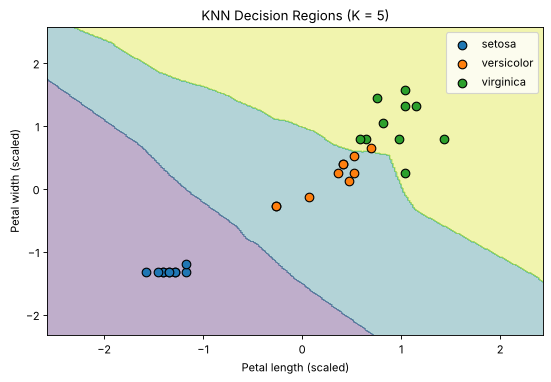

In [11]:
pair = iris[["petal_length", "petal_width"]].to_numpy()
p_train, p_test, q_train, q_test = train_test_split(pair, labels, test_size=0.2, random_state=42, stratify=labels)
pair_scaler = StandardScaler().fit(p_train)
p_train, p_test = pair_scaler.transform(p_train), pair_scaler.transform(p_test)
pair_model = KNeighborsClassifier(n_neighbors=best_k).fit(p_train, q_train)

gx, gy = np.meshgrid(np.linspace(p_test[:, 0].min() - 1, p_test[:, 0].max() + 1, 300),
                     np.linspace(p_test[:, 1].min() - 1, p_test[:, 1].max() + 1, 300))
names = list(pair_model.classes_)
region = pair_model.predict(np.c_[gx.ravel(), gy.ravel()])
region = np.array([names.index(r) for r in region]).reshape(gx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(gx, gy, region, alpha=0.35, cmap="viridis")
for i, name in enumerate(names):
    plt.scatter(p_test[q_test == name, 0], p_test[q_test == name, 1], edgecolor="black", s=60, label=name)
plt.title("KNN Decision Regions (K = " + str(best_k) + ")")
plt.xlabel("Petal length (scaled)")
plt.ylabel("Petal width (scaled)")
plt.legend()
plt.show()
pair_acc = accuracy_score(q_test, pair_model.predict(p_test))
print("Accuracy with two features:", round(pair_acc, 4))

**Result:** Using only petal length and petal width the model gets 96.67% accuracy on the test set. The plot shows three clear regions, one for each species, with a small overlap between versicolor and virginica.